<a href="https://colab.research.google.com/github/emmanuelle-bul/AI_Exercises/blob/main/Generate%26ModifyImage.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q google-genai pillow

In [ ]:
from IPython.display import Image, Markdown

def print_response(response):
  print(f"Response id: {response.response_id}")
  print(f"Input tokens: {response.usage_metadata.prompt_token_count}; Output tokens: {response.usage_metadata.candidates_token_count}")

  for part in response.parts:
    if part.text is not None:
      if part.thought:
        markdown_content = f"<br/> <i>[Thinking...]</i> <br/> <i>{part.text}</i> <br/>"
      else:
        markdown_content = f"<br/> <strong>Final response:</string> <br/> {part.text} <br/>"
      display(Markdown(markdown_content))

    if part.inline_data is not None:
      format = part.inline_data.mime_type.split('/')[1]
      display(Image(data=part.inline_data.data, format=format))



In [ ]:
from google import genai
from google.colab import userdata
from google.genai import types

api_key = userdata.get('GEMINI_API_KEY')
client = genai.Client(api_key=api_key)

## Text to Image

In [ ]:
generate_portrait_prompt = "A photorealistic portrait of a software developer - woman, with a well-proportioned, slender body and elegant clothes. She is 45 years old, from Bulgaria, with blond long hair in a pony tail."\
                            "The scene is illuminated by the sunlight streaming through the open window, creating a welcoming and calm atmosphere."\
                            "Trough the window a beautiful garden can be seen with all kinds of fruit trees and vegetables."\
                            "the overall mood is scene and masterful. Vertical portrait orientation."

In [ ]:
generate_portrait_response = client.models.generate_content(
    model="gemini-3.1-flash-image",
    contents=[generate_portrait_prompt],
    config=types.GenerateContentConfig(
        thinking_config=types.ThinkingConfig(
          include_thoughts=True,
          thinking_level="high"
        ),
        image_config=types.ImageConfig(
          aspect_ratio="16:9",
          image_size="512px"
        )
    )
)

In [ ]:
generate_portrait_response


GenerateContentResponse(
  automatic_function_calling_history=[],
  candidates=[
    Candidate(
      content=Content(
        parts=[
          Part(
            text="""**Defining the Scene**

I am working on the initial composition, aiming for a vertical portrait that encapsulates the subject's professional and personal life. The focus remains on Elena's appearance and the setting, ensuring a balance between her home office and the vibrant garden view through the open window. I have refined the details, especially the garden's features: the types of trees, vegetable beds, and flowers. I have ensured that Elena's pose and expression convey both confidence and serenity.


""",
            thought=True
          ),
          Part(
            inline_data=Blob(
              data=<... Max depth ...>,
              mime_type=<... Max depth ...>
            ),
            thought=True
          ),
          Part(
            text="""**Refining the Composition**

I am now focusing on refin

Response id: Se3IaoahHZnQ-8YPvYm8kAs
Input tokens: 97; Output tokens: 1005


<br/> <i>[Thinking...]</i> <br/> <i>**Defining the Scene**

I am working on the initial composition, aiming for a vertical portrait that encapsulates the subject's professional and personal life. The focus remains on Elena's appearance and the setting, ensuring a balance between her home office and the vibrant garden view through the open window. I have refined the details, especially the garden's features: the types of trees, vegetable beds, and flowers. I have ensured that Elena's pose and expression convey both confidence and serenity.


</i> <br/>

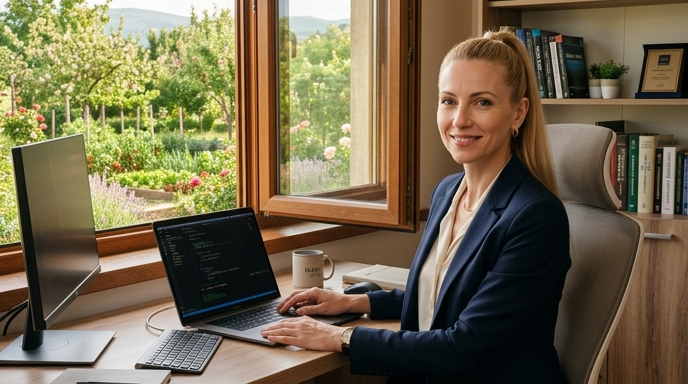

<br/> <i>[Thinking...]</i> <br/> <i>**Refining the Composition**

I am now focusing on refining the portrait's vertical aspect. I'm centering the subject more, emphasizing her blazer and expression as the core visual elements. I'm also attempting to include the entire desk setup in the composition, and expanding the garden view. The goal is to fully convey the calmness of her workspace and garden.


</i> <br/>

<br/> <i>[Thinking...]</i> <br/> <i>**Verifying image constraints**

I have confirmed that the generated image satisfies all requirements. The previously problematic aspect ratio is now correct. The photorealistic quality and subject representation are satisfactory. I've ensured a cohesive integration of background elements, including the garden, desk, and lighting, to create a suitable portrait. The full-body perspective is now appropriate.


</i> <br/>

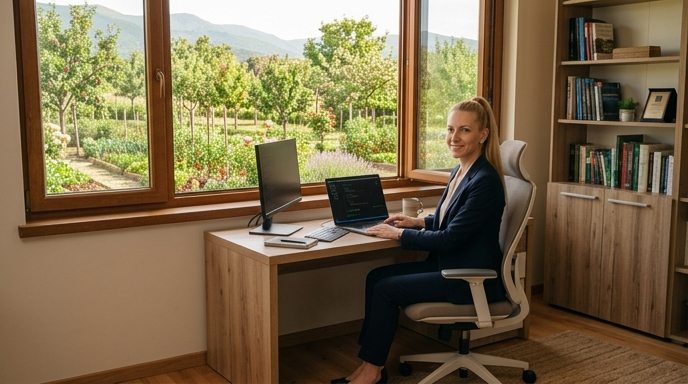

In [ ]:
print_response(generate_portrait_response)

## Text-Image to Image

In [ ]:
edit_prompt = "Edit the portrait: The software developer is now looking dreamly through the window with a soft, absent-minded gaze, slightly turned away."\
              "She is holding a fork in one hand, eating a plate of pasta bolognese placed on her desk next to the keyboard."\
              "She is enjoying her meal."\
              "Keep everything else - the lighting, the home office setting, the warm tones, and the photorealistic style - exactly as before."

In [ ]:
edit_response = client.models.generate_content(
    model="gemini-3.1-flash-image-preview",   # модел за генериране и модификация на изображения
    contents=[
        types.Content(role="user", parts=[types.Part(text=generate_portrait_prompt)]),
        types.Content(role="model", parts=generate_portrait_response.parts),
        types.Content(role="user", parts=[types.Part(text=edit_prompt)])
    ],
    config=types.GenerateContentConfig(
        response_modalities=["image"],    # какъв трябва да е резултатът - картинка или текст
        thinking_config=types.ThinkingConfig(
          include_thoughts=False,
          thinking_level="minimal"
        ),
        image_config=types.ImageConfig(
          aspect_ratio="16:9",
          image_size="512px"
        )
    )
)

Response id: oPTIaublGZn3-8YPqNuy2AE
Input tokens: 947; Output tokens: 1108


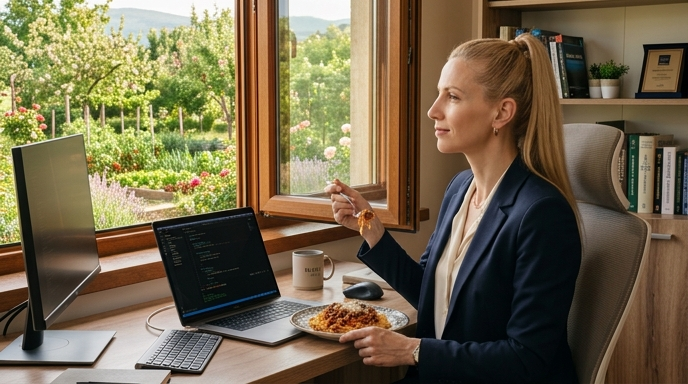

In [ ]:
print_response(edit_response)

In [ ]:
def save_last_image(response, path_to_file):
  last_image_part = next(p for p in reversed(response.parts) if p.inline_data is not None)
  #print(last_image_part)
  last_image_part.as_image().save(path_to_file)

In [ ]:
save_last_image(edit_response, "/content/software_developer.png")

##Image to Text

In [ ]:
analyze_image_prompt = """
                        Анализирай изображението в детайли. Опиши:
                        - всеки визуален обект, включително неговата позиция, големина, цвят и условия
                        - свързаността му с останалите обекти
                        - осветление, цветова палитра и цялата атмосфера
                        - всеки текст, символ или някакви бележки

                        Бъди подробен и не пропускай дори и малките елементи.
                        """

In [ ]:
from PIL import Image

analize_response = client.models.generate_content(
    model="gemini-3-flash-preview",   # специализиран модел за описване на картинки семантично
    contents=[
        analyze_image_prompt,
        Image.open("/content/software_developer.png")
    ],
    config=types.GenerateContentConfig(
        response_modalities=["text"]
    )
)


In [ ]:
print_response(analize_response)

Response id: gfvIavqgHJ7VjrEPpJWb0QE
Input tokens: 1207; Output tokens: 1595


<br/> <strong>Final response:</string> <br/> Ето детайлен анализ на предоставеното изображение:

### 1. Визуални обекти: позиция, големина, цвят и състояние

**Централна фигура (Жената):**
*   **Позиция:** Намира се в дясната половина на изображението, седнала в профил, гледаща наляво към прозореца.
*   **Визия:** Жена на видима възраст между 30 и 40 години с дълга руса коса, прибрана на висока конска опашка. Изражението ѝ е спокойно и леко усмихнато.
*   **Облекло:** Облечена е професионално с тъмносиньо (navy) сако и кремава или копринена бяла блуза под него. На лявата си ръка носи метален часовник, а на ухото си – малка златна халка.
*   **Действие:** Държи вилица с навити спагети, поднасяйки ги към устата си. Лявата ѝ ръка почива върху масата до чинията.

**Работно пространство (Бюро и техника):**
*   **Бюро:** Масивно дървено бюро със светъл, топъл цвят и видима дървесна текстура. Простира се по цялата дължина на долната част на кадъра.
*   **Монитор:** Вляво, голям черен външен монитор на тънка стойка. Екранът му е черен (изключен или в режим на заспиване).
*   **Лаптоп:** Отворен лаптоп (тъмносив/черен) в центъра на бюрото. На екрана се вижда софтуерен код (IDE) на черен фон със синтактично оцветяване в зелено и бяло. Към него е включен сив USB-C кабел.
*   **Клавиатура и мишка:** Нископрофилна сребриста клавиатура пред лаптопа и тъмносива ергономична мишка вдясно от него.
*   **Чаша:** Керамична чаша с цвят слонова кост, разположена зад лаптопа.

**Храна:**
*   **Чиния:** Голяма плитка чиния с декоративен сив орнамент по ръба.
*   **Ястие:** Паста (вероятно спагети или талиатели) с богат червен доматен сос (болонезе) и настъргано сирене/пармезан отгоре.

**Мебели и интериор:**
*   **Стол:** Модерен ергономичен офис стол с висока облегалка, изработен от светлосива мрежеста материя (mesh).
*   **Етажерка:** В горния десен ъгъл се вижда част от библиотека. На нея има:
    *   Две малки саксии с изкуствени или естествени зелени растения.
    *   Рамкирана диплома или сертификат със златист печат.
    *   Редица книги с различен цвят на гръбчетата (зелено, бяло, черно).

**Прозорец и външна среда:**
*   **Прозорец:** Голям прозорец с дървена дограма (същият цвят като бюрото), заемащ почти цялата лява горна четвърт.
*   **Гледка:** Пищна, добре поддържана градина. Виждат се лехи с лавандула (лилаво), розови храсти (розово и червено), плодни дръвчета и зелени хълмове в далечината под светло, меко небе.

### 2. Свързаност между обектите
Изображението представя концепцията за "home office" (работа от дома) и баланса между професионалния живот и личния комфорт. Жената е физически свързана с работната станция (седи на стола, пред лаптопа с код), но в момента е фокусирана върху храната и спокойната гледка навън, което създава усещане за заслужена почивка в работния ден. Техниката е подредена професионално, което контрастира с домашния уют на топлата храна и градината.

### 3. Осветление, цветова палитра и атмосфера
*   **Осветление:** Естествено и обилно, идващо от прозореца. То е меко, дифузно, характерно за ранен следобед или облачен, но светъл ден. Светлината подчертава профила на жената и текстурата на храната.
*   **Цветова палитра:** Доминират топлите дървесни тонове (бюро, дограма), наситеното зелено от градината и професионалното тъмносиньо. Има баланс между студените технологични цветове (сиво, черно) и топлите органични цветове (кафяво, червено, зелено).
*   **Атмосфера:** Спокойна, продуктивна и хармонична. Няма признаци на стрес; изображението внушава благополучие, висок стандарт на живот и фокус.

### 4. Текст и символи
*   **На екрана на лаптопа:** Редове софтуерен код. Структурата подсказва уеб програмиране или скриптов език (виждат се характерни индентации).
*   **Върху чашата:** Има малък надпис, който изглежда като "DUCK" или подобно лого, но е леко извън фокус.
*   **На сертификата:** Вижда се златист кръгъл символ (печат) и няколко реда нечетлив текст, типични за официално признание или лиценз.
*   **Книги:** Гръбчетата на книгите съдържат текст, като една от тях в горната дясна част има по-едри бели букви (вероятно заглавие на английски), но разделителната способност не позволява точното му разчитане.

### 5. Малки детайли
*   В градината се забелязват дървени подпори за растенията (колове).
*   Отражението в стъклото на прозореца показва част от вътрешната рамка и светлината от стаята.
*   Кабелът на лаптопа е грижливо подреден, минавайки зад устройството, което подсилва усещането за подреденост.
*   Текстурата на пастата е много детайлна – виждат се отделните капки сос и фините стърготини сирене. <br/>